Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8244 - loss: 0.6543 - val_accuracy: 0.9096 - val_loss: 0.3191
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9160 - loss: 0.2929 - val_accuracy: 0.9258 - val_loss: 0.2543
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9324 - loss: 0.2368 - val_accuracy: 0.9379 - val_loss: 0.2112
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9424 - loss: 0.2014 - val_accuracy: 0.9461 - val_loss: 0.1838
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9495 - loss: 0.1772 - val_accuracy: 0.9532 - val_loss: 0.1623
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9548 - loss: 0.1577 - val_accuracy: 0.9548 - val_loss: 0.1531
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9602 - loss: 0.1426 - val_accuracy: 0.9593 - val_loss: 0.1411
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9627 - loss: 0.1303 - 

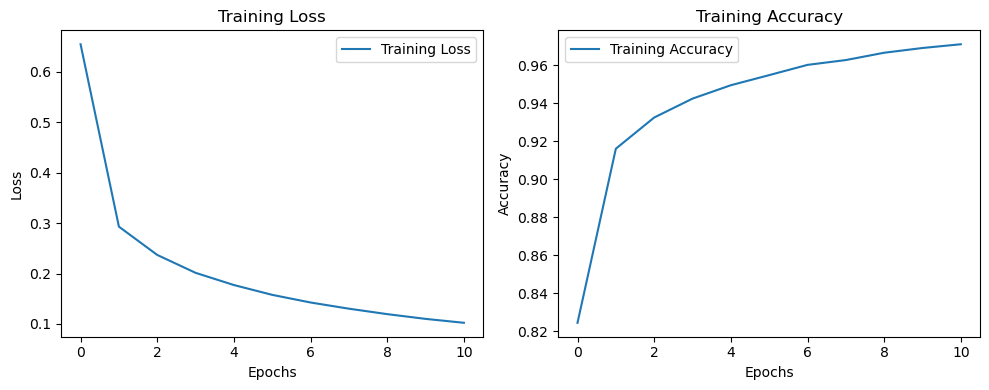

In [1]:
# Step 1: Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD

# Step 2: Load training and testing data
train = pd.read_csv("mnist_train.csv")
test = pd.read_csv("mnist_test.csv")

# Separate features and labels
x_train = train.iloc[:, 1:].values
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values
y_test = test.iloc[:, 0].values

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Step 3: Define FNN architecture
model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

# Compile model using SGD
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Step 4: Train model for 11 epochs
history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_data=(x_test, y_test)
)

# Step 5: Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Step 6: Plot training loss and accuracy
plt.figure(figsize=(10, 4))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()

# Accuracy graph
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.legend()

plt.tight_layout()
plt.show()
